In [ ]:
# ==================================================
# 01. CONFIGURACIÓN INICIAL - TOKENIZACIÓN BPE
# ==================================================

!pip -q install sentencepiece

from google.colab import drive
from pathlib import Path

import pandas as pd
import sentencepiece as spm
import csv
import random
import numpy as np

# Montar Google Drive
drive.mount("/content/drive")

# Reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Configuración del tokenizador
VOCAB_SIZE = 16000
MAX_LENGTH = 80

# Directorio principal
BASE_DIR = Path(
    "/content/drive/MyDrive/"
    "Proyecto_traductor/traductor_optimizado"
)

RAW_DIR = BASE_DIR / "datasets" / "raw"
TOKENIZER_DIR = BASE_DIR / "tokenizador"

TOKENIZER_DIR.mkdir(parents=True, exist_ok=True)

# Verificar archivos originales
for archivo in ["train.tsv", "val.tsv", "test.tsv"]:
    ruta = RAW_DIR / archivo
    print(f"{archivo}: {'OK' if ruta.exists() else 'NO ENCONTRADO'}")

print("\nConfiguración:")
print("Vocabulario:", VOCAB_SIZE)
print("Longitud máxima:", MAX_LENGTH)
print("SentencePiece:", spm.__version__)
print("Directorio tokenizador:", TOKENIZER_DIR)

Mounted at /content/drive
train.tsv: OK
val.tsv: OK
test.tsv: OK

Configuración:
Vocabulario: 16000
Longitud máxima: 80
SentencePiece: 0.2.2
Directorio tokenizador: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/tokenizador


In [ ]:
# ==================================================
# 02. CARGAR TRAIN Y CREAR CORPUS BILINGÜE
# ==================================================

import unicodedata

# Cargar únicamente el conjunto de entrenamiento
train_df = pd.read_csv(
    RAW_DIR / "train.tsv",
    sep="\t",
    header=None,
    names=["en", "es", "id_original"],
    dtype=str,
    keep_default_na=False,
    quoting=csv.QUOTE_NONE,
    on_bad_lines="error"
)

# Normalización mínima, sin alterar el significado
def normalizar_texto(texto):
    texto = unicodedata.normalize("NFC", texto)
    return " ".join(texto.split())

# Archivo de entrada para SentencePiece
CORPUS_PATH = TOKENIZER_DIR / "corpus_bpe.txt"

lineas_escritas = 0

with open(CORPUS_PATH, "w", encoding="utf-8") as f:
    for en, es in train_df[["en", "es"]].itertuples(
        index=False, name=None
    ):
        en = normalizar_texto(en)
        es = normalizar_texto(es)

        if en and es:
            f.write(en + "\n")
            f.write(es + "\n")
            lineas_escritas += 2

# Verificación
print("Pares originales:", f"{len(train_df):,}")
print("Líneas escritas:", f"{lineas_escritas:,}")
print("Corpus:", CORPUS_PATH)
print("Tamaño (MB):", round(
    CORPUS_PATH.stat().st_size / (1024 ** 2), 2
))

print("\nPrimeras 6 líneas:")
with open(CORPUS_PATH, "r", encoding="utf-8") as f:
    for _ in range(6):
        print(repr(f.readline().strip()))

Pares originales: 792,070
Líneas escritas: 1,584,140
Corpus: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/tokenizador/corpus_bpe.txt
Tamaño (MB): 53.52

Primeras 6 líneas:
'She might be the future Mrs. Max Russo.'
'Tengo que conocerla.'
"This isn't getting us anywhere. - No, of course it isn't."
'Esto no conduce a ninguna parte.'
"It's the moment you've trained for."
'Es el momento para el que has entrenado.'


In [ ]:
# ==================================================
# 03. ENTRENAR TOKENIZADOR SENTENCEPIECE BPE
# ==================================================

MODEL_PREFIX = TOKENIZER_DIR / "tokenizer"

spm.SentencePieceTrainer.train(
    input=str(CORPUS_PATH),
    model_prefix=str(MODEL_PREFIX),

    # Algoritmo y vocabulario
    model_type="bpe",
    vocab_size=VOCAB_SIZE,

    # Tokens especiales
    pad_id=0,
    unk_id=1,
    bos_id=2,
    eos_id=3,

    pad_piece="<pad>",
    unk_piece="<unk>",
    bos_piece="<bos>",
    eos_piece="<eos>",

    # Configuración
    character_coverage=1.0,
    normalization_rule_name="identity",
    max_sentence_length=4096,
    num_threads=4,

    # Reproducibilidad y uso de todo el corpus
    input_sentence_size=0,
    shuffle_input_sentence=False,

    # Evitar fragmentación innecesaria de números
    split_digits=False
)

print("\nENTRENAMIENTO BPE FINALIZADO")

print("Modelo:", MODEL_PREFIX.with_suffix(".model"))
print("Vocabulario:", MODEL_PREFIX.with_suffix(".vocab"))


ENTRENAMIENTO BPE FINALIZADO
Modelo: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/tokenizador/tokenizer.model
Vocabulario: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/tokenizador/tokenizer.vocab


In [ ]:
# ==================================================
# 04. VALIDACIÓN DEL TOKENIZADOR BPE
# ==================================================

# Cargar el tokenizador entrenado
sp = spm.SentencePieceProcessor(
    model_file=str(TOKENIZER_DIR / "tokenizer.model")
)

# Verificar configuración
print("VOCABULARIO")
print("Tamaño:", sp.get_piece_size())
print("PAD ID:", sp.pad_id())
print("UNK ID:", sp.unk_id())
print("BOS ID:", sp.bos_id())
print("EOS ID:", sp.eos_id())

assert sp.get_piece_size() == VOCAB_SIZE
assert sp.pad_id() == 0
assert sp.unk_id() == 1
assert sp.bos_id() == 2
assert sp.eos_id() == 3

# Probar con oraciones de ambos idiomas
ejemplos = [
    "I want to learn machine learning.",
    "Quiero aprender aprendizaje automático.",
    "The university is developing an artificial intelligence project.",
    "La universidad está desarrollando un proyecto de inteligencia artificial."
]

print("\nPRUEBAS DE TOKENIZACIÓN")

for texto in ejemplos:
    tokens = sp.encode(texto, out_type=str)
    ids = sp.encode(texto, out_type=int)
    reconstruido = sp.decode(ids)

    print("\nOriginal:", texto)
    print("Tokens:", tokens)
    print("IDs:", ids)
    print("Cantidad de tokens:", len(ids))
    print("Reconstruido:", reconstruido)
    print("Coincide:", reconstruido == texto)

VOCABULARIO
Tamaño: 16000
PAD ID: 0
UNK ID: 1
BOS ID: 2
EOS ID: 3

PRUEBAS DE TOKENIZACIÓN

Original: I want to learn machine learning.
Tokens: ['▁I', '▁want', '▁to', '▁learn', '▁machine', '▁le', 'arning', '.']
IDs: [29, 287, 44, 2783, 5729, 206, 15364, 15658]
Cantidad de tokens: 8
Reconstruido: I want to learn machine learning.
Coincide: True

Original: Quiero aprender aprendizaje automático.
Tokens: ['▁Quiero', '▁aprender', '▁aprend', 'iza', 'je', '▁autom', 'ático', '.']
IDs: [1158, 5714, 5629, 3749, 631, 7657, 5896, 15658]
Cantidad de tokens: 8
Reconstruido: Quiero aprender aprendizaje automático.
Coincide: True

Original: The university is developing an artificial intelligence project.
Tokens: ['▁The', '▁univers', 'ity', '▁is', '▁develop', 'ing', '▁an', '▁artific', 'ial', '▁intelligence', '▁project', '.']
IDs: [214, 3993, 731, 131, 7682, 48, 155, 12997, 489, 13398, 6682, 15658]
Cantidad de tokens: 12
Reconstruido: The university is developing an artificial intelligence project.
Coi

In [ ]:
# ==================================================
# 05. ANÁLISIS DE LONGITUDES BPE
# ==================================================

import numpy as np
import pandas as pd
import csv

resultados = []

for nombre in ["train", "val", "test"]:

    df = pd.read_csv(
        RAW_DIR / f"{nombre}.tsv",
        sep="\t",
        header=None,
        names=["en", "es", "id_original"],
        dtype=str,
        keep_default_na=False,
        quoting=csv.QUOTE_NONE
    )

    # Longitudes en tokens BPE + BOS y EOS
    long_en = np.array([
        len(sp.encode(texto)) + 2
        for texto in df["en"]
    ])

    long_es = np.array([
        len(sp.encode(texto)) + 2
        for texto in df["es"]
    ])

    # Pares donde ambos idiomas caben en MAX_LENGTH
    validos = (long_en <= MAX_LENGTH) & (long_es <= MAX_LENGTH)

    resultados.append({
        "conjunto": nombre,
        "pares": len(df),
        "media_en": round(long_en.mean(), 2),
        "media_es": round(long_es.mean(), 2),
        "p95_en": int(np.percentile(long_en, 95)),
        "p95_es": int(np.percentile(long_es, 95)),
        "p99_en": int(np.percentile(long_en, 99)),
        "p99_es": int(np.percentile(long_es, 99)),
        "max_en": int(long_en.max()),
        "max_es": int(long_es.max()),
        "pares_mayores_80": int((~validos).sum()),
        "cobertura_pct": round(validos.mean() * 100, 2)
    })

resumen_longitudes = pd.DataFrame(resultados)

print("ANÁLISIS DE LONGITUDES BPE")
print("Longitud máxima configurada:", MAX_LENGTH)
print("Incluye tokens BOS y EOS\n")

display(resumen_longitudes)

ANÁLISIS DE LONGITUDES BPE
Longitud máxima configurada: 80
Incluye tokens BOS y EOS



,conjunto,pares,media_en,media_es,p95_en,p95_es,p99_en,p99_es,max_en,max_es,pares_mayores_80,cobertura_pct
0,train,792070,11.86,11.09,24,22,32,30,65,76,0,100.0
1,val,44004,11.90,11.14,24,22,32,31,57,54,0,100.0
2,test,44004,11.88,11.13,24,22,31,30,47,63,0,100.0


In [ ]:
# ==================================================
# 06. GUARDAR CONFIGURACIÓN DEL TOKENIZADOR
# ==================================================

import json

CONFIG_DIR = BASE_DIR / "configuracion"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

config_tokenizador = {
    "tipo": "sentencepiece_bpe",
    "vocabulario_compartido": True,
    "vocab_size": sp.get_piece_size(),
    "pad_id": sp.pad_id(),
    "unk_id": sp.unk_id(),
    "bos_id": sp.bos_id(),
    "eos_id": sp.eos_id(),
    "max_length": MAX_LENGTH,
    "normalization_rule": "identity",
    "modelo": "tokenizador/tokenizer.model",
    "dataset": "OpenSubtitles",
    "entrenado_con": "datasets/raw/train.tsv",
    "seed_proyecto": SEED
}

CONFIG_PATH = CONFIG_DIR / "tokenizador_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(
        config_tokenizador,
        f,
        ensure_ascii=False,
        indent=4
    )

print("Configuración guardada correctamente:")
print(CONFIG_PATH)

print("\nContenido:")
print(json.dumps(config_tokenizador, indent=4, ensure_ascii=False))

Configuración guardada correctamente:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/configuracion/tokenizador_config.json

Contenido:
{
    "tipo": "sentencepiece_bpe",
    "vocabulario_compartido": true,
    "vocab_size": 16000,
    "pad_id": 0,
    "unk_id": 1,
    "bos_id": 2,
    "eos_id": 3,
    "max_length": 80,
    "normalization_rule": "identity",
    "modelo": "tokenizador/tokenizer.model",
    "dataset": "OpenSubtitles",
    "entrenado_con": "datasets/raw/train.tsv",
    "seed_proyecto": 42
}


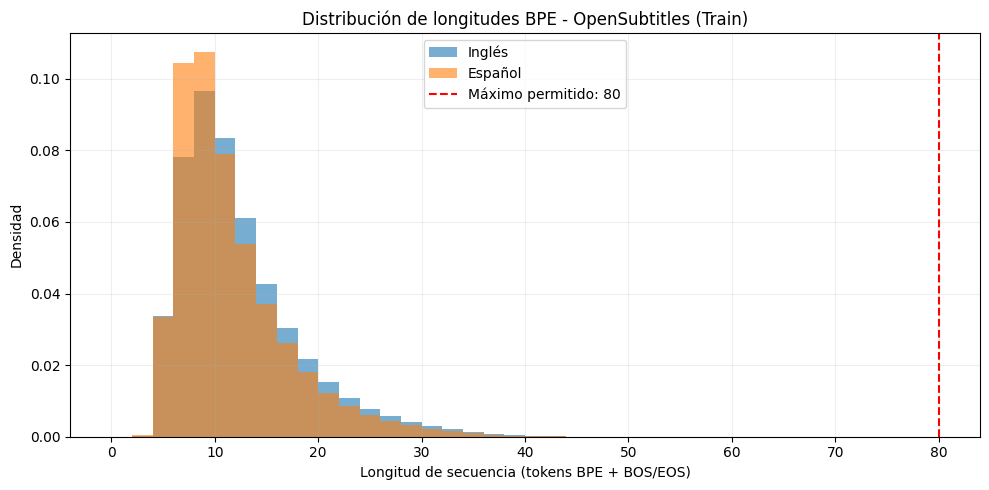

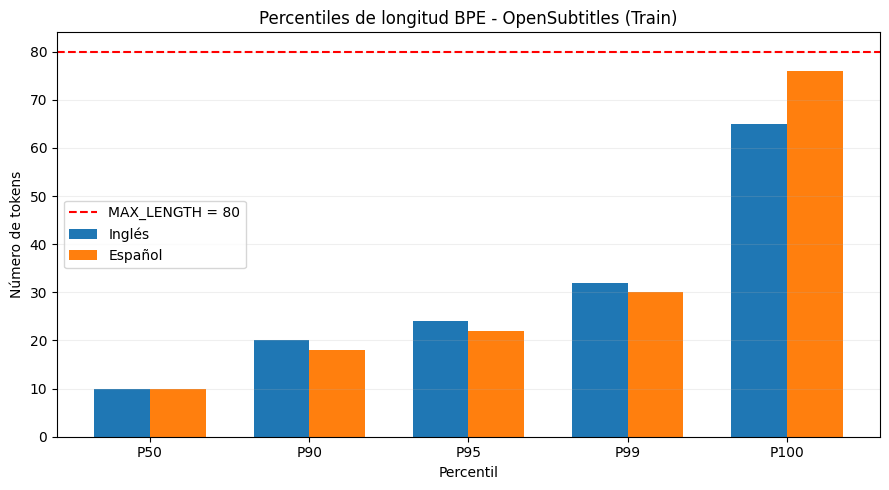

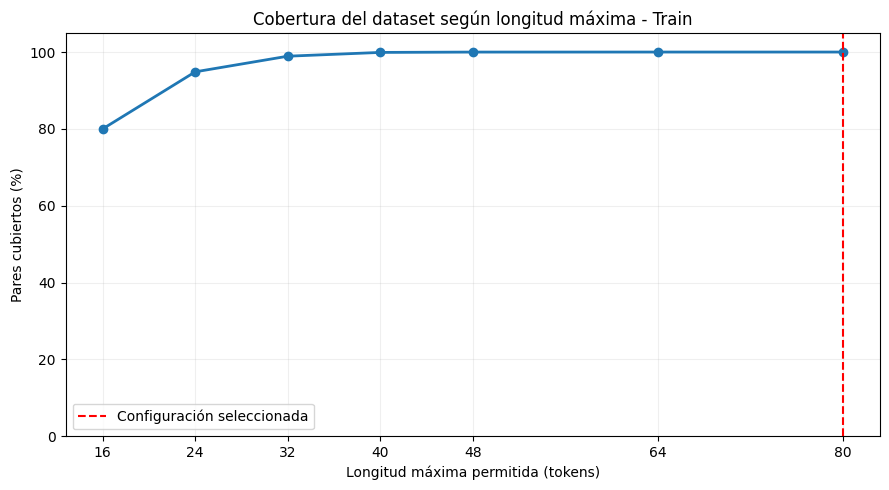


GRÁFICOS GUARDADOS:
- cobertura_max_length.png
- distribucion_longitudes_bpe.png
- percentiles_longitudes_bpe.png


In [ ]:
# ==================================================
# 07. GRÁFICOS PARA EL INFORME - TOKENIZACIÓN BPE
# ==================================================

import matplotlib.pyplot as plt
import numpy as np

GRAFICOS_DIR = BASE_DIR / "resultados" / "graficos"
GRAFICOS_DIR.mkdir(parents=True, exist_ok=True)

# Analizar longitudes del conjunto de entrenamiento
long_en = np.array([
    len(sp.encode(texto)) + 2
    for texto in train_df["en"]
])

long_es = np.array([
    len(sp.encode(texto)) + 2
    for texto in train_df["es"]
])

# GRÁFICO 1: Distribución de longitudes BPE
fig, ax = plt.subplots(figsize=(10, 5))

bins = np.arange(0, 82, 2)

ax.hist(long_en, bins=bins, alpha=0.6,
        label="Inglés", density=True)
ax.hist(long_es, bins=bins, alpha=0.6,
        label="Español", density=True)

ax.axvline(MAX_LENGTH, color="red", linestyle="--",
           label=f"Máximo permitido: {MAX_LENGTH}")

ax.set(
    title="Distribución de longitudes BPE - OpenSubtitles (Train)",
    xlabel="Longitud de secuencia (tokens BPE + BOS/EOS)",
    ylabel="Densidad"
)
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    GRAFICOS_DIR / "distribucion_longitudes_bpe.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# GRÁFICO 2: Percentiles de longitud
percentiles = [50, 90, 95, 99, 100]

valores_en = np.percentile(long_en, percentiles)
valores_es = np.percentile(long_es, percentiles)

x = np.arange(len(percentiles))
ancho = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(x - ancho/2, valores_en, ancho, label="Inglés")
ax.bar(x + ancho/2, valores_es, ancho, label="Español")

ax.axhline(MAX_LENGTH, color="red", linestyle="--",
           label="MAX_LENGTH = 80")

ax.set_xticks(x)
ax.set_xticklabels([f"P{p}" for p in percentiles])
ax.set(
    title="Percentiles de longitud BPE - OpenSubtitles (Train)",
    xlabel="Percentil",
    ylabel="Número de tokens"
)
ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(
    GRAFICOS_DIR / "percentiles_longitudes_bpe.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# GRÁFICO 3: Cobertura según longitud máxima
longitud_pares = np.maximum(long_en, long_es)
limites = [16, 24, 32, 40, 48, 64, 80]

coberturas = [
    np.mean(longitud_pares <= limite) * 100
    for limite in limites
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(limites, coberturas, marker="o", linewidth=2)
ax.axvline(MAX_LENGTH, color="red", linestyle="--",
           label="Configuración seleccionada")

ax.set(
    title="Cobertura del dataset según longitud máxima - Train",
    xlabel="Longitud máxima permitida (tokens)",
    ylabel="Pares cubiertos (%)"
)
ax.set_ylim(0, 105)
ax.set_xticks(limites)
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    GRAFICOS_DIR / "cobertura_max_length.png",
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("\nGRÁFICOS GUARDADOS:")
for archivo in sorted(GRAFICOS_DIR.glob("*.png")):
    print("-", archivo.name)